# Company A Telecom Customer Churn Analysis

**GCI World 2026 – Final Assignment**

This notebook runs the end-to-end churn analysis using the reusable modules in the `src/` folder.

## Project workflow
1. Load and validate the Client and Record datasets.
2. Examine target distribution, data quality and original features.
3. Explore engineered customer-behaviour features.
4. Train and compare six classification models.
5. Evaluate the selected model and inspect feature importance.
6. Rank customers by churn risk and estimate top-decile lift.

> Run this notebook from the project root folder so that imports such as `src.data` work correctly. The notebook expects the project data in `telecom/` and saves outputs in `outputs/`.


## 1. Import libraries and project modules

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the project root is available for imports.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError(
        "Run this notebook from the project root folder "
        "(the folder containing src/ and telecom/)."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_data, check_target

from src.eda import (
    save_data_profile,
    plot_target_distribution,
    plot_missing_values,
    numeric_summary,
    plot_numeric_by_target,
    plot_distributions,
    plot_correlation_heatmap,
    plot_churn_by_category,
    plot_scatter,
    plot_engineered_features,
    engineered_feature_summary,
)

from src.modeling import train_compare_models, feature_importance
from src.evaluation import evaluate_selected_model
from src.business import make_risk_ranking, top_group_lift
from src.narrative import metrics_summary, business_summary

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Project root:", PROJECT_ROOT)


Project root: c:\Users\princ\Company_A_Telecom_Project


## 2. Load and validate the datasets

The `load_data()` function is expected to return the original Client data, Record data and merged modelling dataset.

In [2]:
client, record, df = load_data()

print("Client shape:", client.shape)
print("Record shape:", record.shape)
print("Merged shape:", df.shape)

display(df.head())


Client shape: (100000, 50)
Record shape: (100000, 51)
Merged shape: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


## 3. Examine the churn target

Check the number and proportion of churn and non-churn customers before proceeding.

In [3]:
target_counts, target_proportions = check_target(df)

print("Target counts:")
display(target_counts)

print("Target proportions:")
display(target_proportions)


Target counts:


churn
0    50438
1    49562
Name: count, dtype: int64

Target proportions:


churn
0    0.5044
1    0.4956
Name: proportion, dtype: float64

## 4. Data quality and descriptive statistics

In [4]:
profile = save_data_profile(df)

print("Data profile:")
display(profile.head(20))

print("Numerical summary:")
display(numeric_summary(df))


Data profile:


,dtype,missing_count,missing_percent,unique_values
numbcars,float64,49366,49.37,3
dwllsize,str,38308,38.31,15
HHstatin,str,37923,37.92,6
ownrent,str,33706,33.71,2
dwlltype,str,31909,31.91,2
lor,float64,30190,30.19,16
income,float64,25436,25.44,9
adults,float64,23019,23.02,6
infobase,str,22079,22.08,2
hnd_webcap,str,10189,10.19,3


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
rev_Mean,99643.0,5.871998e+01,46.291677,-6.167500e+00,3.326000e+01,4.819500e+01,7.075000e+01,3.843262e+03
mou_Mean,99643.0,5.135599e+02,525.168140,0.000000e+00,1.507500e+02,3.555000e+02,7.030000e+02,1.220675e+04
totmrc_Mean,99643.0,4.617914e+01,23.623489,-2.691500e+01,3.000000e+01,4.499000e+01,5.999000e+01,4.099900e+02
da_Mean,99643.0,8.888279e-01,2.177619,0.000000e+00,0.000000e+00,2.475000e-01,9.900000e-01,1.593900e+02
ovrmou_Mean,99643.0,4.107225e+01,97.296150,0.000000e+00,0.000000e+00,2.750000e+00,4.200000e+01,4.320750e+03
ovrrev_Mean,99643.0,1.355956e+01,30.500885,0.000000e+00,0.000000e+00,1.000000e+00,1.443750e+01,1.102400e+03
vceovr_Mean,99643.0,1.329506e+01,30.056089,0.000000e+00,0.000000e+00,6.825000e-01,1.402500e+01,8.960875e+02
datovr_Mean,99643.0,2.613177e-01,3.126531,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.235400e+02
roam_Mean,99643.0,1.286405e+00,14.711374,0.000000e+00,0.000000e+00,0.000000e+00,2.350000e-01,3.685200e+03
change_mou,99109.0,-1.393382e+01,276.087509,-3.875000e+03,-8.700000e+01,-6.250000e+00,6.300000e+01,3.121925e+04


## 5. Original exploratory data analysis

The following plots examine the target distribution, missingness, selected numerical variables, correlations and available categorical variables.

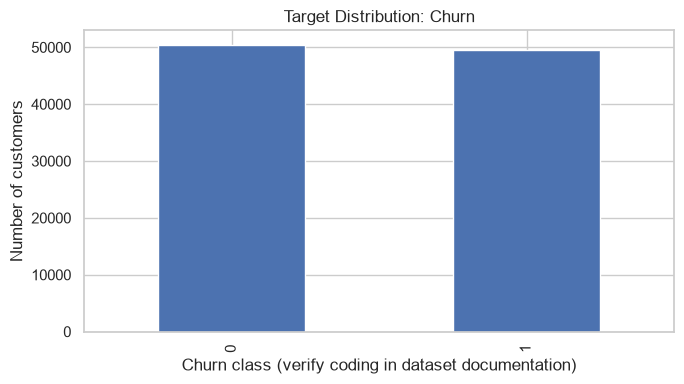

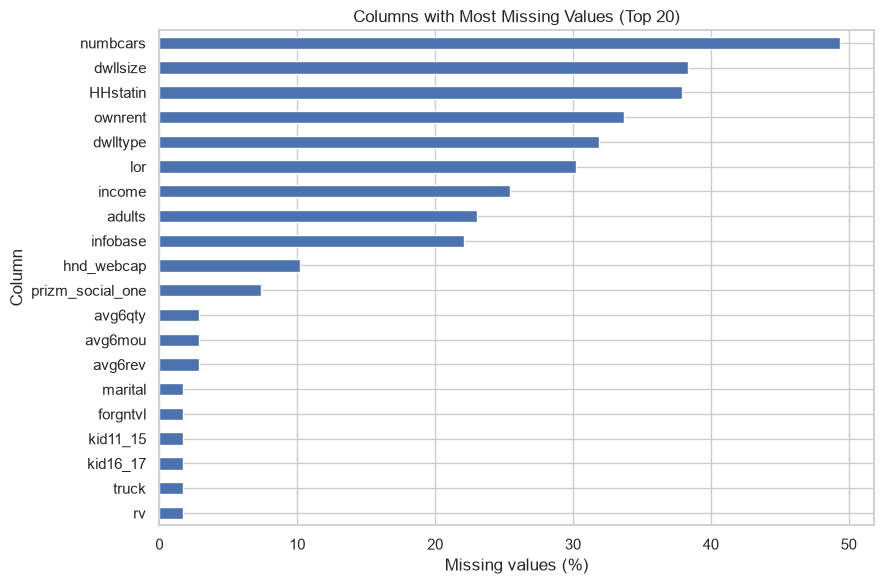

WindowsPath('C:/Users/princ/Company_A_Telecom_Project/outputs/figures/missing_values.png')

In [5]:
plot_target_distribution(df)
plot_missing_values(df)


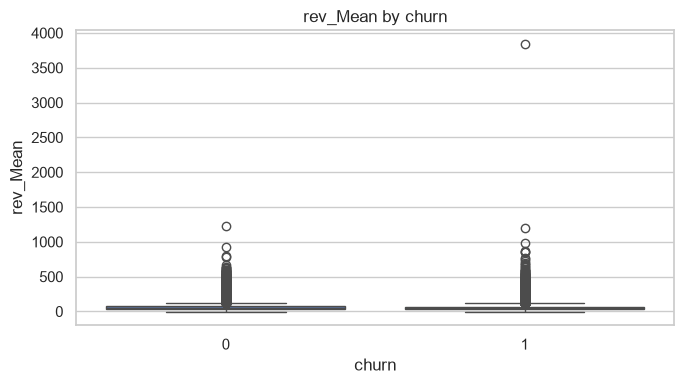

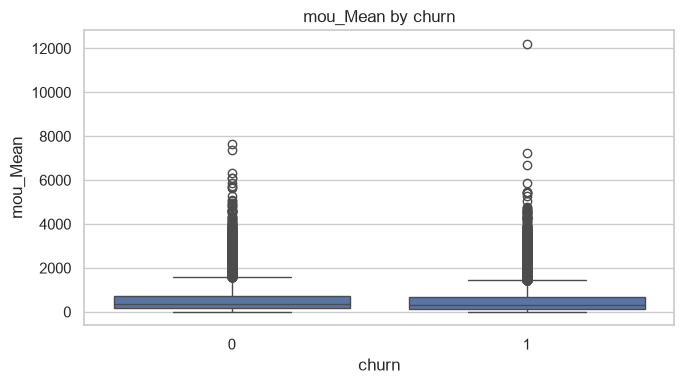

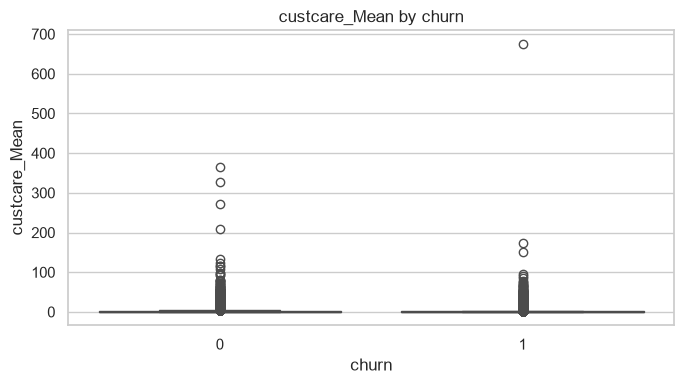

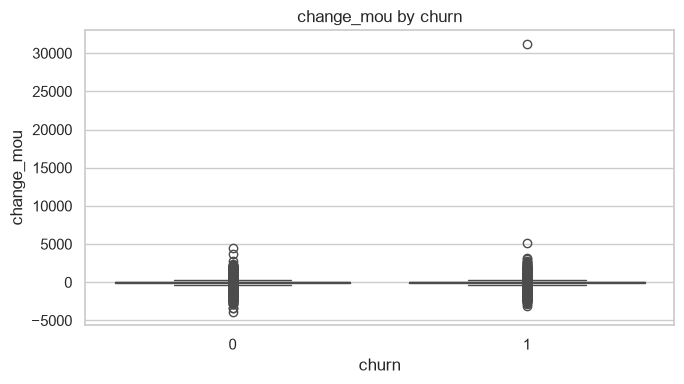

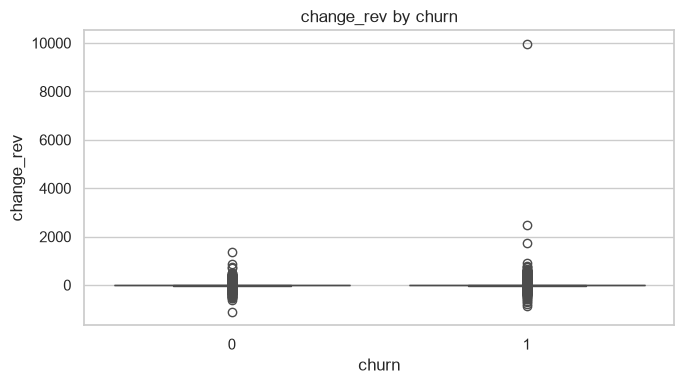

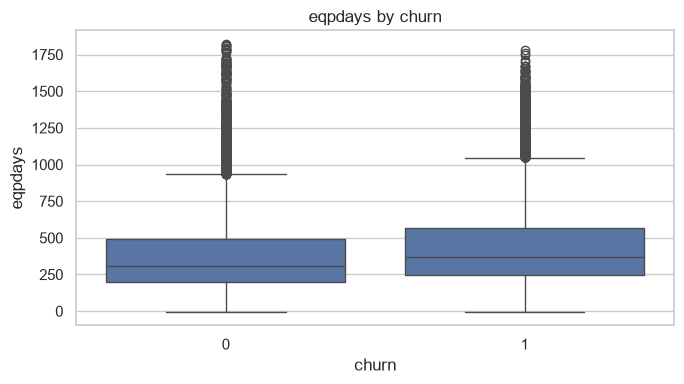

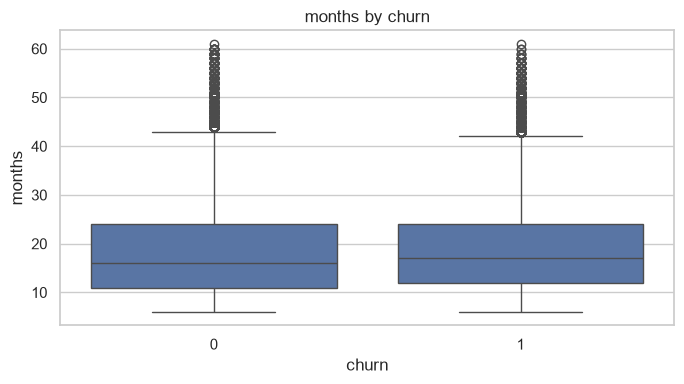

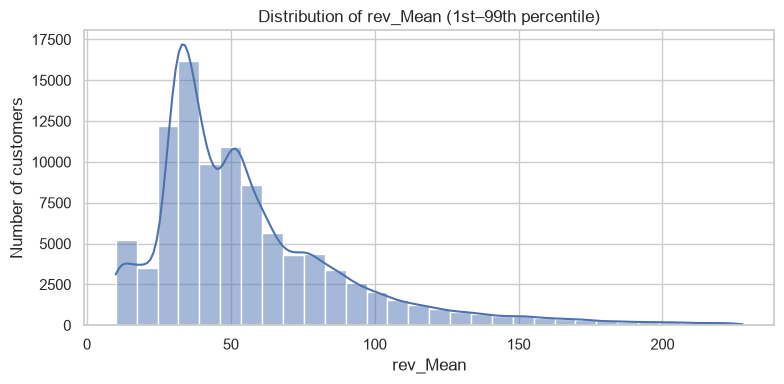

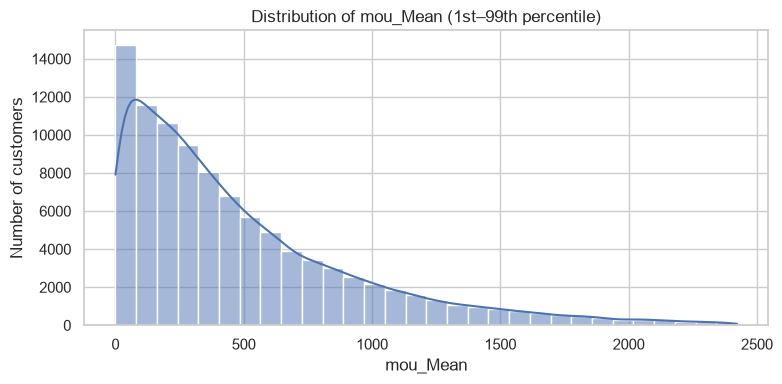

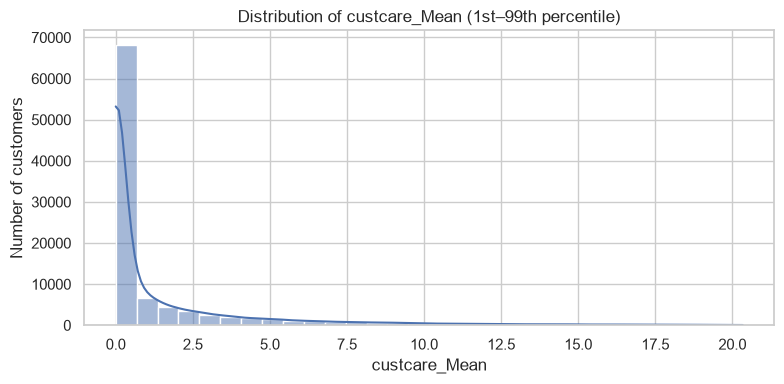

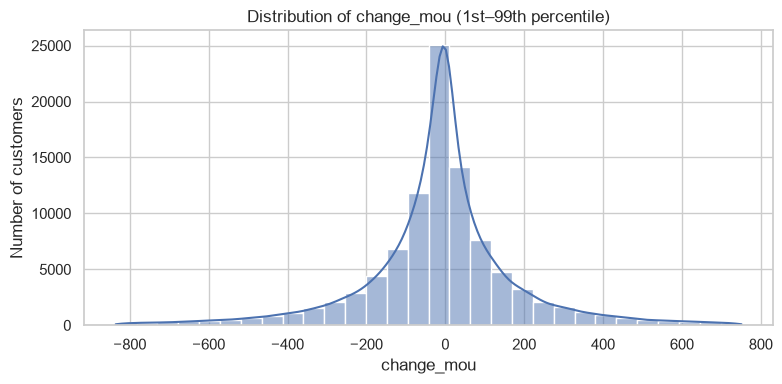

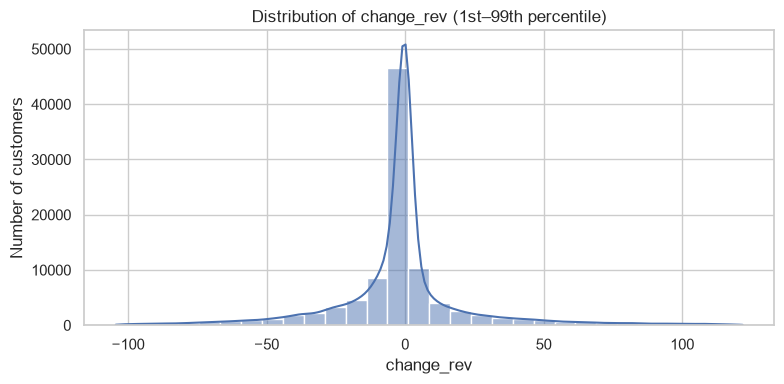

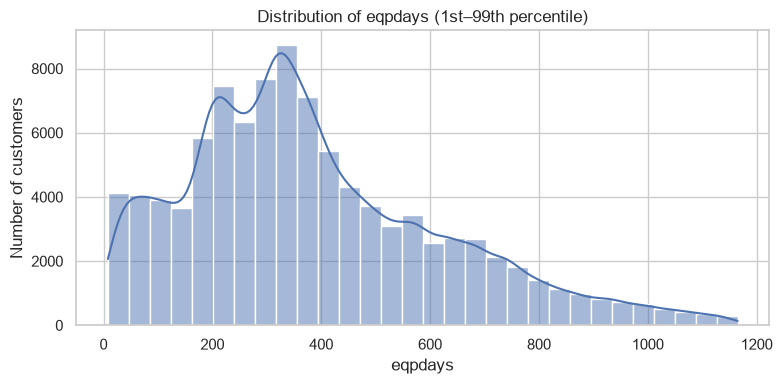

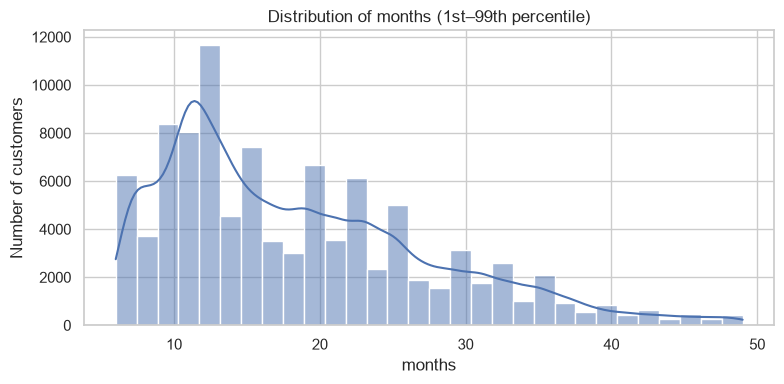

In [6]:
eda_features = [
    "rev_Mean",
    "mou_Mean",
    "custcare_Mean",
    "change_mou",
    "change_rev",
    "eqpdays",
    "months",
]

# Keep only columns present in this dataset.
eda_features = [col for col in eda_features if col in df.columns]

if eda_features:
    plot_numeric_by_target(df, eda_features)
    plot_distributions(df, eda_features)
else:
    print("None of the selected numerical EDA columns were found.")


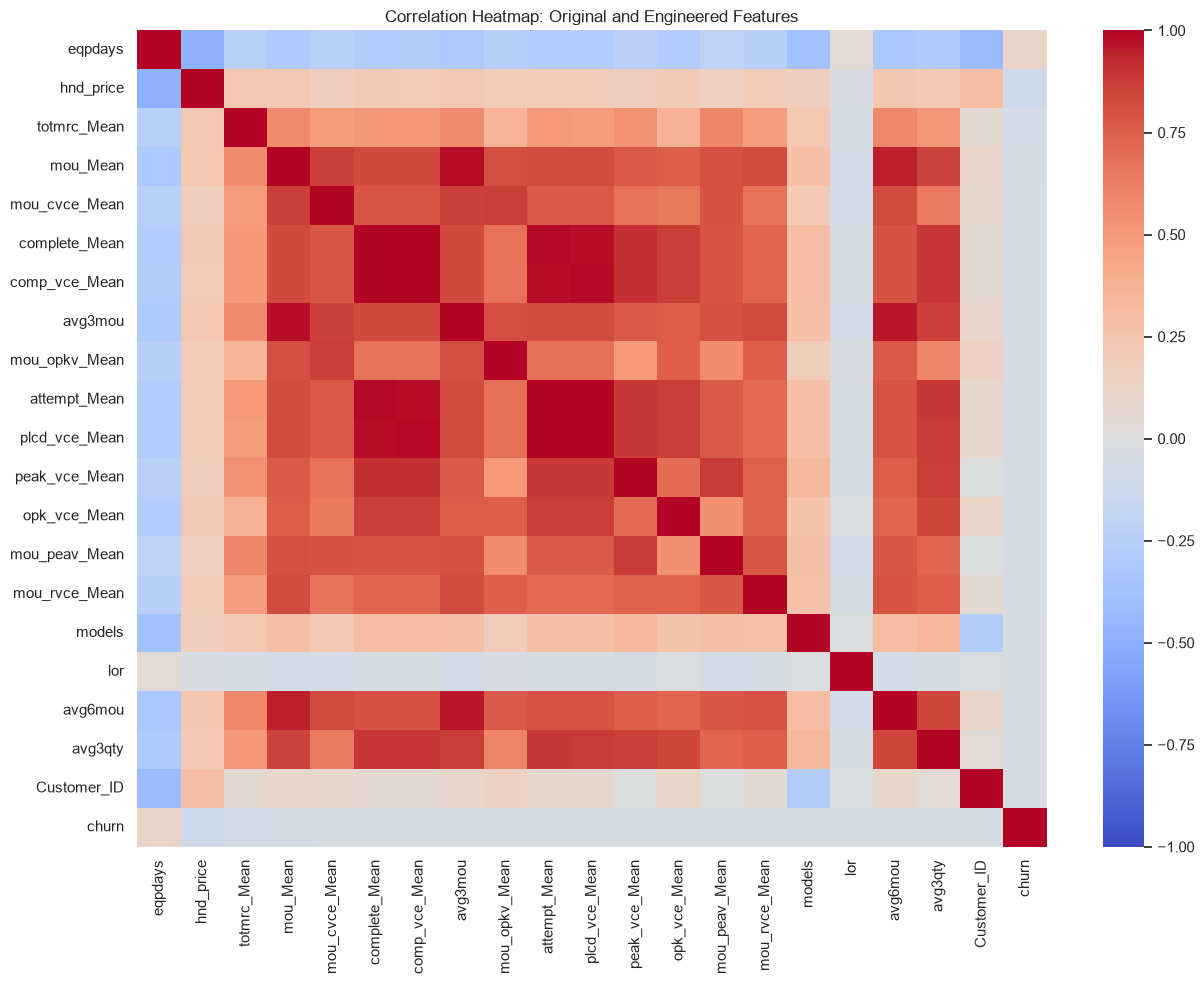

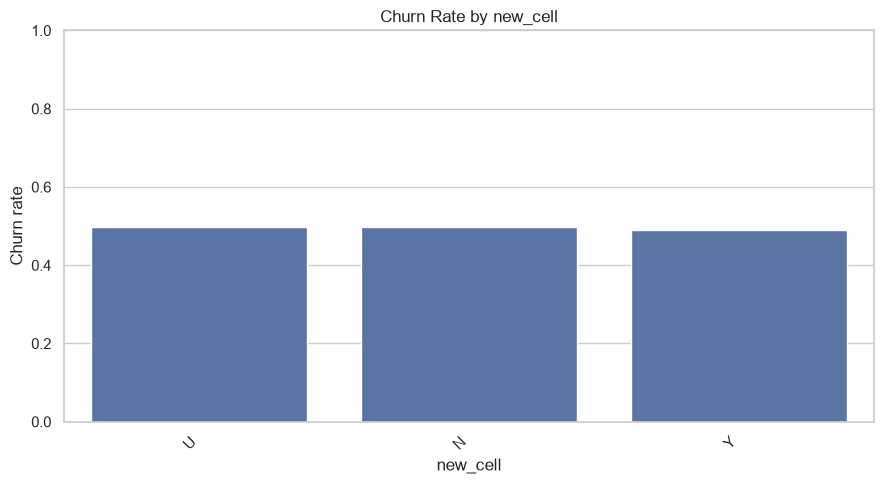

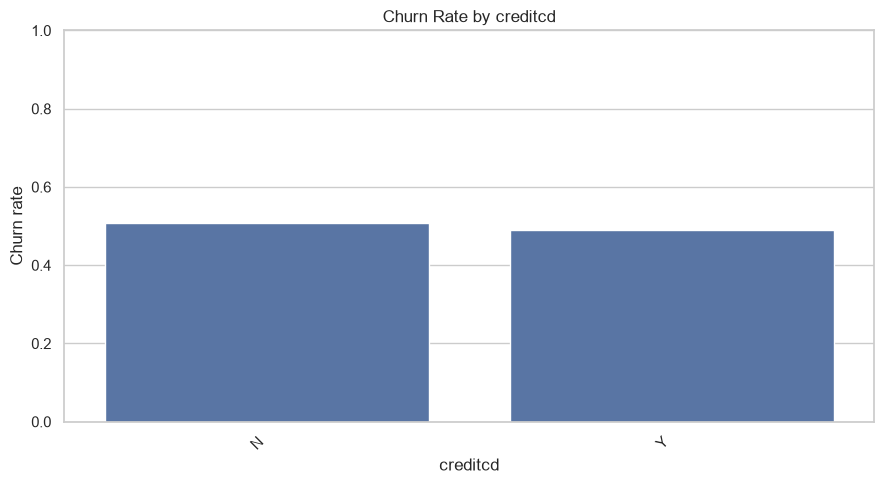

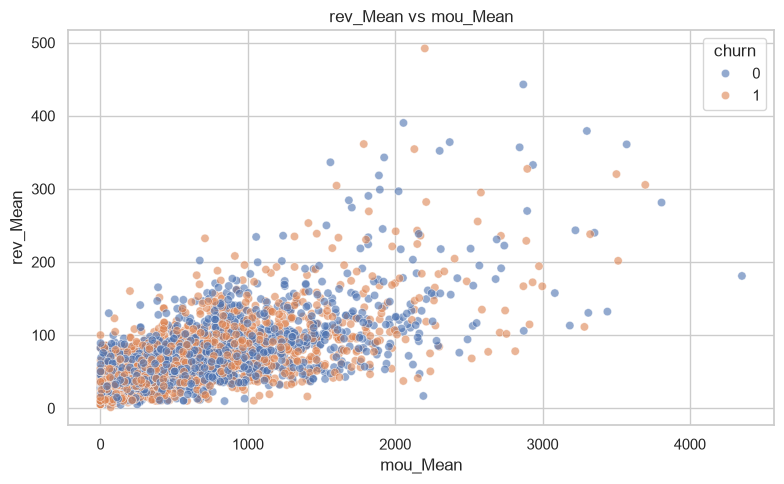

In [7]:
plot_correlation_heatmap(df)

for feature in ["new_cell", "creditcd"]:
    if feature in df.columns:
        plot_churn_by_category(df, feature)

if "mou_Mean" in df.columns and "rev_Mean" in df.columns:
    plot_scatter(df, "mou_Mean", "rev_Mean")


## 6. Exploratory analysis of engineered features

The feature-engineering module creates additional customer-behaviour variables. The engineered features are used here for exploration, and the modelling pipeline should apply the same feature engineering internally.

Review the generated feature profile and summary before interpreting the plots. Check that the source columns and formulas are appropriate for the dataset and business context.


Engineered numerical features:
['revenue_change_ratio', 'customer_care_usage_ratio', 'usage_change_ratio', 'recent_vs_six_month_usage', 'revenue_per_minute']

Engineered categorical features:
['equipment_age_group', 'tenure_group']


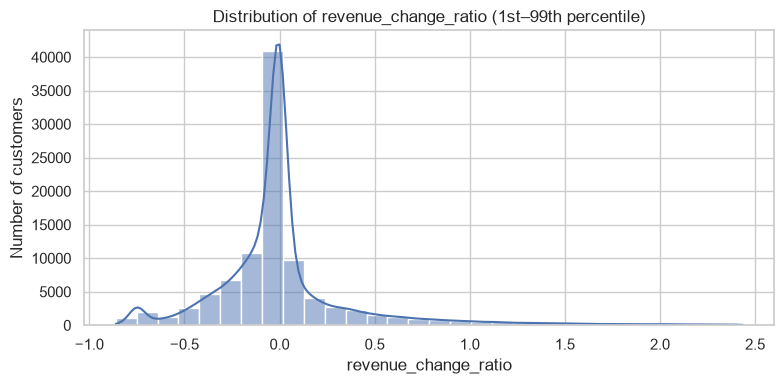

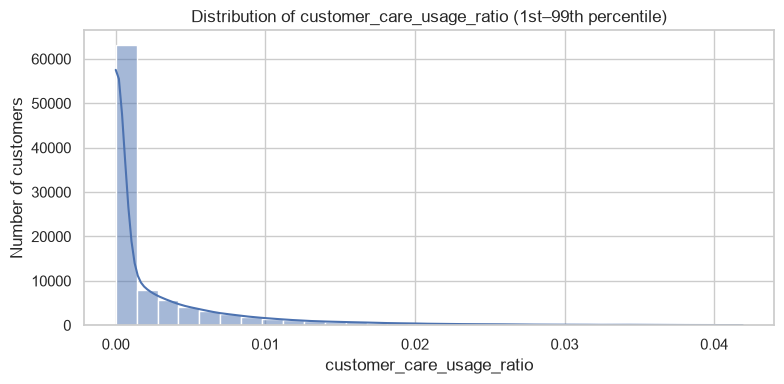

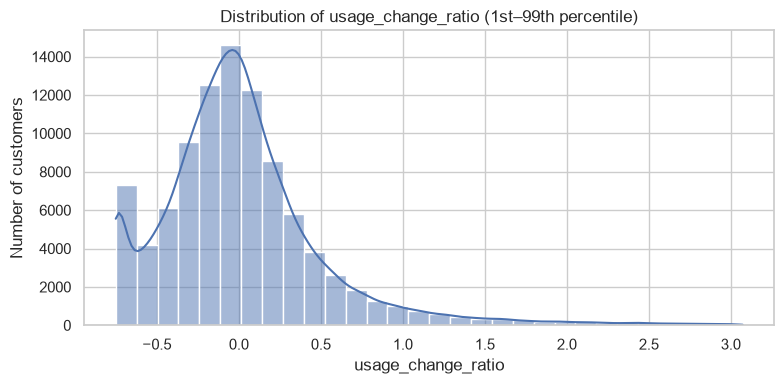

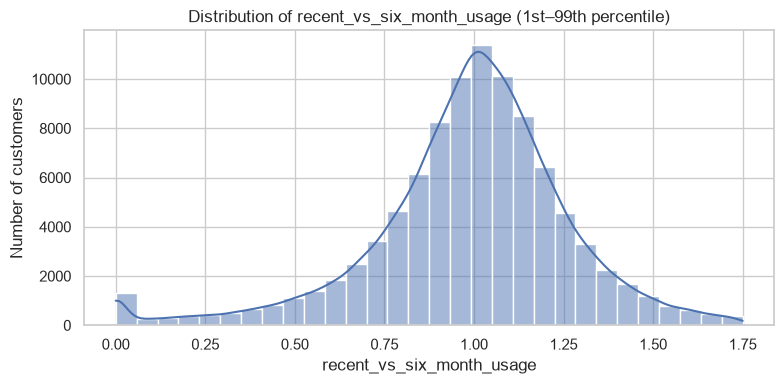

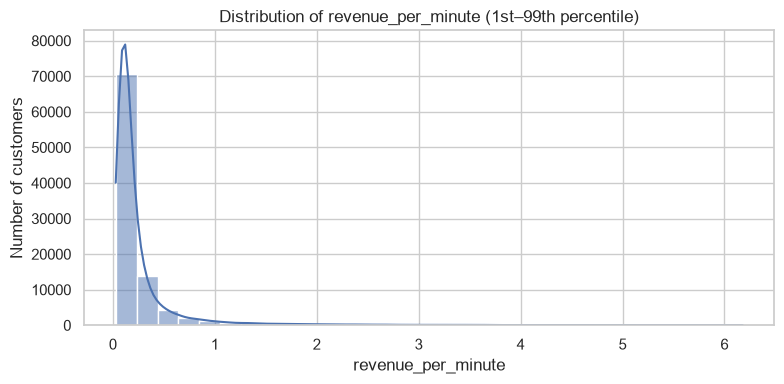

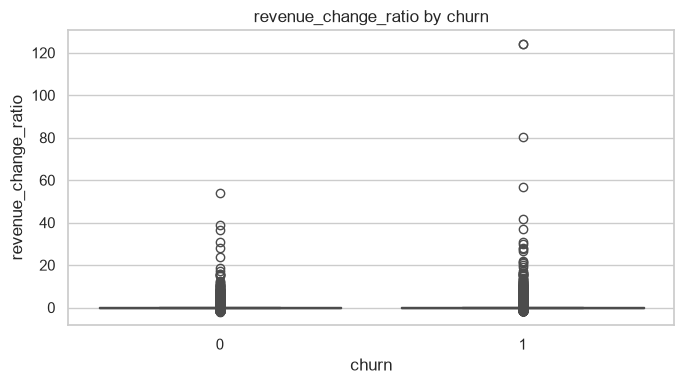

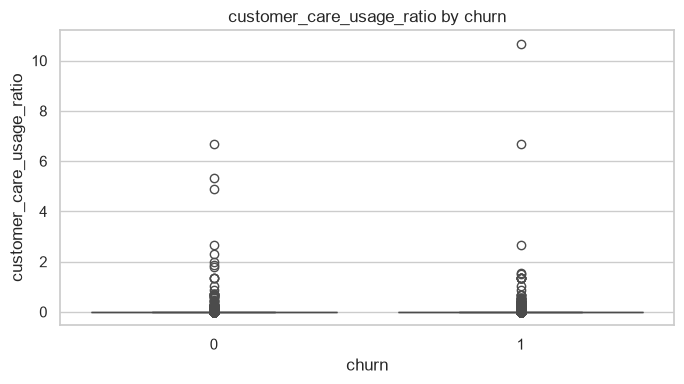

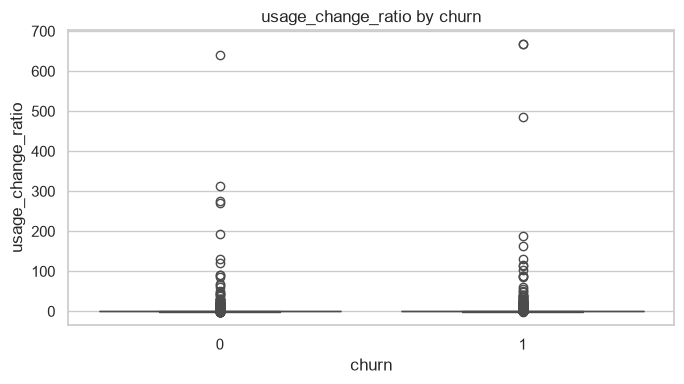

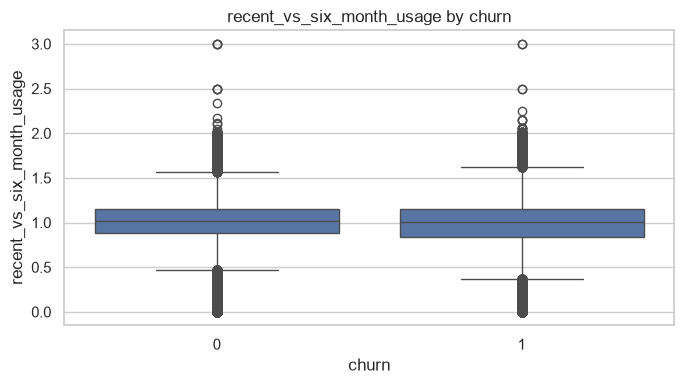

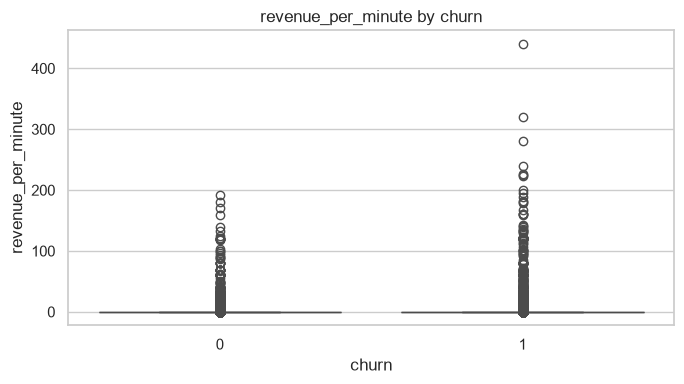

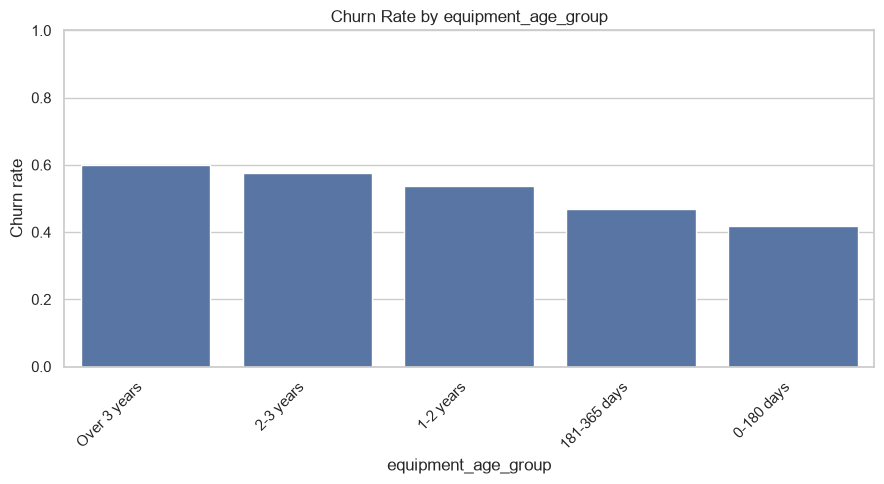

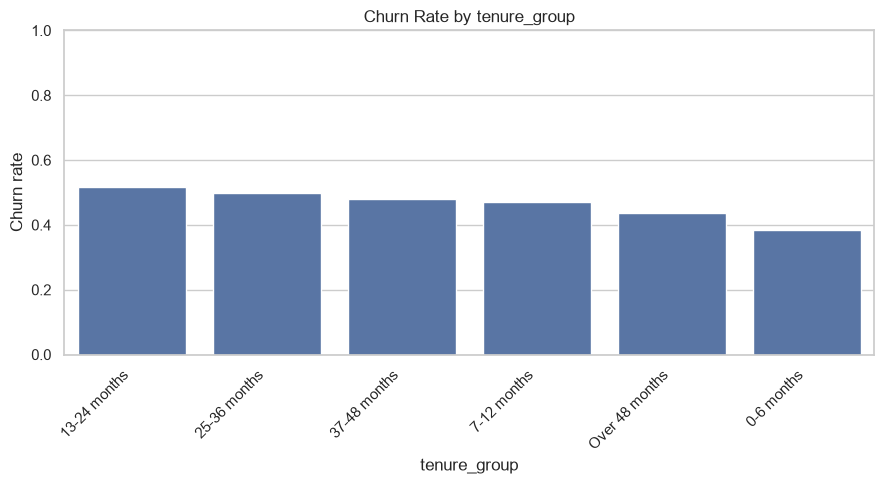

Engineered feature profile:


,dtype,missing_count,missing_percent,unique_values
revenue_change_ratio,float64,891,0.89,66011
customer_care_usage_ratio,float64,1972,1.97,33244
usage_change_ratio,float64,2608,2.61,76214
recent_vs_six_month_usage,float64,3557,3.56,54991
revenue_per_minute,float64,1972,1.97,94463
equipment_age_group,object,1,0.00,5
tenure_group,object,0,0.00,6


Engineered dataset shape: (100000, 107)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,...,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,revenue_change_ratio,customer_care_usage_ratio,usage_change_ratio,recent_vs_six_month_usage,revenue_per_minute,equipment_age_group,tenure_group
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,...,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,-0.633250,0.000000,-0.578125,0.844720,0.109453,181-365 days,Over 48 months
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,...,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1.274687,0.003452,1.745082,0.639413,0.119094,181-365 days,Over 48 months
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,...,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,0.000000,0.000000,-0.354167,1.090909,1.657561,Over 3 years,Over 48 months
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,...,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,0.000000,0.000000,-0.187500,0.160000,5.066667,Over 3 years,Over 48 months
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,

In [8]:
engineered_df, engineered_profile = plot_engineered_features(df)

print("Engineered feature profile:")
display(engineered_profile.head(20))

print("Engineered dataset shape:", engineered_df.shape)
display(engineered_df.head())


Engineered feature summary:


,Feature,Mean,Median,Missing_Percent,Unique_Values
0,revenue_change_ratio,0.055,-0.009,0.891,66011
1,customer_care_usage_ratio,0.004,0.000,1.972,33244
2,usage_change_ratio,0.133,-0.043,2.608,76214
3,recent_vs_six_month_usage,0.996,1.012,3.557,54991
4,revenue_per_minute,0.576,0.139,1.972,94463


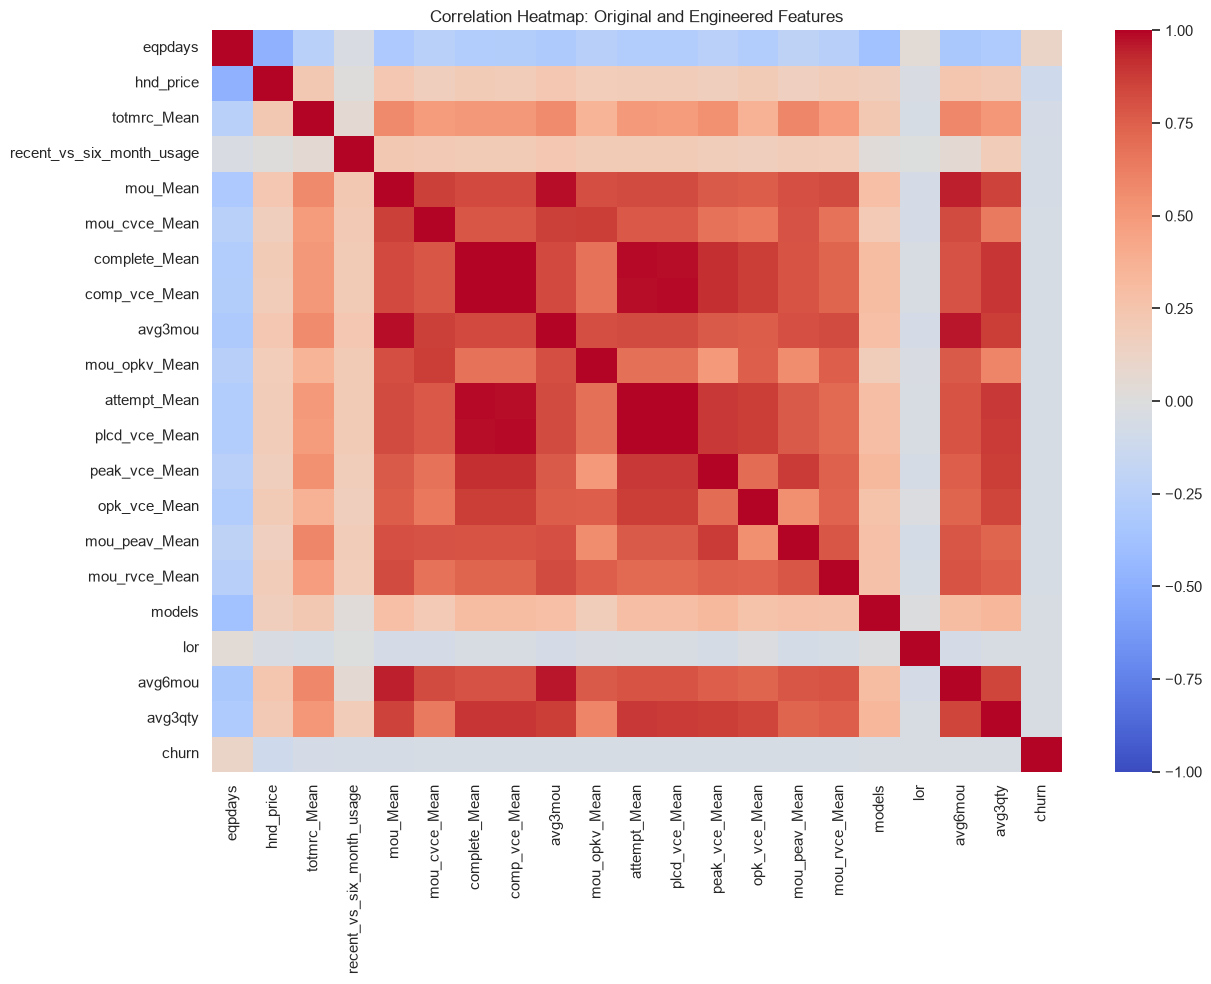

WindowsPath('C:/Users/princ/Company_A_Telecom_Project/outputs/figures/correlation_heatmap.png')

In [9]:
engineered_summary = engineered_feature_summary(df)

print("Engineered feature summary:")
display(engineered_summary)

# Correlations among original and engineered numerical variables.
plot_correlation_heatmap(engineered_df)


## 7. Train and compare six churn-classification models

The modelling module is responsible for preprocessing, train/test separation, model fitting and producing the comparison metrics. Run the model comparison once and retain its result for the evaluation and business-analysis sections.

In [12]:
model_results = train_compare_models(df)

metrics = model_results["metrics"]

print("Model comparison:")
display(metrics)



Training Logistic Regression...
Logistic Regression: validation threshold=0.347, test ROC-AUC=0.6340

Training Decision Tree...
Decision Tree: validation threshold=0.250, test ROC-AUC=0.6344

Training Random Forest...
Random Forest: validation threshold=0.384, test ROC-AUC=0.6846

Training AdaBoost...
AdaBoost: validation threshold=0.374, test ROC-AUC=0.6439

Training Gradient Boosting...
Gradient Boosting: validation threshold=0.391, test ROC-AUC=0.6832

Training HistGradientBoosting...
HistGradientBoosting: validation threshold=0.381, test ROC-AUC=0.6981
Model comparison:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_Average_Precision
0,HistGradientBoosting,0.380759,0.611967,0.571759,0.864887,0.688418,0.698081,0.689519
1,Random Forest,0.383847,0.585267,0.549347,0.908535,0.684693,0.684582,0.672603
2,Gradient Boosting,0.391161,0.594133,0.556616,0.890309,0.684984,0.683198,0.672317
3,AdaBoost,0.373685,0.556900,0.530136,0.932275,0.675915,0.643880,0.631329
4,Decision Tree,0.250000,0.541433,0.521101,0.923465,0.666246,0.634381,0.618171
5,Logistic Regression,0.347179,0.541733,0.520945,0.937588,0.669757,0.633997,0.608307


## 8. Select and evaluate the best-performing model

The code below follows the project workflow: the first row of the sorted model-comparison table is treated as the selected model.

Selected model: HistGradientBoosting
Selected threshold: 0.38075894697937435
Selected model: HistGradientBoosting
Decision threshold: 0.3808
              precision    recall  f1-score   support

     Class 0       0.73      0.36      0.49     15131
     Class 1       0.57      0.86      0.69     14869

    accuracy                           0.61     30000
   macro avg       0.65      0.61      0.59     30000
weighted avg       0.65      0.61      0.59     30000



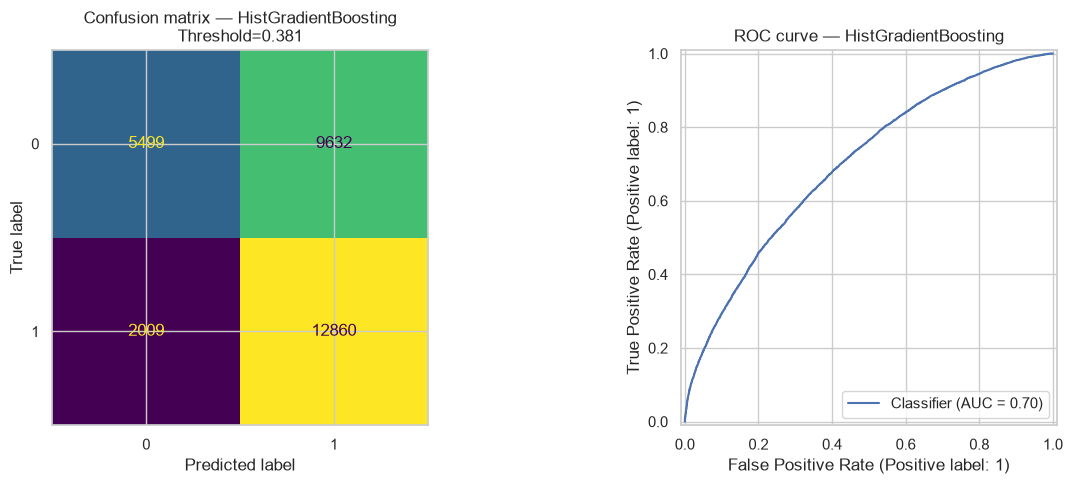

Model summary:
The HistGradientBoosting baseline achieved ROC-AUC 0.698, F1 0.688, precision 0.572, and recall 0.865 on a held-out test set. These scores describe predictive performance on this split; they do not prove that a retention intervention will cause customers to stay.


In [13]:
best_name = metrics.iloc[0]["Model"]

print("Selected model:", best_name)
print("Selected threshold:", model_results["thresholds"][best_name])

evaluate_selected_model(model_results, best_name)

print("Model summary:")
print(metrics_summary(metrics.iloc[0]))


## 9. Feature importance

Feature importance is model-dependent. The helper function may support only some fitted estimators or pipelines. If importance is not available for the selected model, the notebook reports that rather than stopping the analysis.

In [14]:
try:
    importance = feature_importance(model_results["models"][best_name])
    print("Top features:")
    display(importance.head(20))
except (ValueError, AttributeError, KeyError, TypeError) as error:
    print("Feature importance unavailable for", best_name)
    print("Reason:", error)


Feature importance unavailable for HistGradientBoosting
Reason: This estimator does not expose feature_importances_.


## 10. Business analysis: customer risk ranking

The business module ranks customers using the selected model's churn-risk predictions. The top 10% group is then evaluated using the project's lift function.

Interpret the result as a prioritisation aid, not as proof that a customer will churn or that a particular intervention will prevent churn.

In [15]:
ranking = make_risk_ranking(model_results, best_name)

print("Customer risk ranking preview:")
display(ranking.head(10))

lift = top_group_lift(ranking, share=0.10)

print("Top-risk group summary:")
display(lift if isinstance(lift, (pd.DataFrame, pd.Series)) else pd.DataFrame([lift]))

print("Business interpretation:")
print(business_summary(lift))


Customer risk ranking preview:


,Actual_Churn,Predicted_Risk,Risk_Decile
70682,1,0.960170,10
57207,1,0.946821,10
69672,1,0.939378,10
23733,1,0.937835,10
42920,1,0.937352,10
21088,1,0.933001,10
85999,1,0.932362,10
11694,1,0.931934,10
2510,1,0.931670,10
20990,1,0.929752,10


Top-risk group summary:


,test_rows,target_share,selected_rows,observed_positive_rate_top_group,observed_positive_rate_full_test,share_of_actual_positives_captured
0,30000,0.1,3000,0.810333,0.495633,0.163495


Business interpretation:
The highest-risk 10% of the test set contained 3,000 records. The observed positive rate in this group was 81.0%, compared with 49.6% in the full test set. This group captured 16.3% of positive cases in the test set. Treat this as retrospective targeting analysis, not evidence of causal campaign impact.


## 11. Final results and saved outputs

Review the selected model, threshold, comparison metrics and business findings. Figures and tables are saved by the project modules under `outputs/figures/` and `outputs/tables/`.

In [16]:
print("Selected model:", best_name)
print("Selected threshold:", model_results["thresholds"][best_name])

print("\nModel comparison:")
display(metrics)

print("\nOutput folders:")
print("Figures:", PROJECT_ROOT / "outputs" / "figures")
print("Tables:", PROJECT_ROOT / "outputs" / "tables")


Selected model: HistGradientBoosting
Selected threshold: 0.38075894697937435

Model comparison:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_Average_Precision
0,HistGradientBoosting,0.380759,0.611967,0.571759,0.864887,0.688418,0.698081,0.689519
1,Random Forest,0.383847,0.585267,0.549347,0.908535,0.684693,0.684582,0.672603
2,Gradient Boosting,0.391161,0.594133,0.556616,0.890309,0.684984,0.683198,0.672317
3,AdaBoost,0.373685,0.556900,0.530136,0.932275,0.675915,0.643880,0.631329
4,Decision Tree,0.250000,0.541433,0.521101,0.923465,0.666246,0.634381,0.618171
5,Logistic Regression,0.347179,0.541733,0.520945,0.937588,0.669757,0.633997,0.608307



Output folders:
Figures: c:\Users\princ\Company_A_Telecom_Project\outputs\figures
Tables: c:\Users\princ\Company_A_Telecom_Project\outputs\tables
